# 08 — Text-only QA with page citations

## Objective

Build the exact text context and response contract for a cited answer, then validate citation parsing and failure handling without pretending that a model provider has already been selected.

## Concept

Grounded generation has two separate responsibilities:

1. provide evidence with stable page identifiers;
2. require the answer to cite only those identifiers.

A syntactically valid citation is not necessarily correct evidence, but citations outside the supplied context can be rejected mechanically.

In [2]:
from pathlib import Path
import re

import pandas as pd
import pymupdf


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"
MODEL_PROVIDER = None
MODEL_NAME = None
TEMPERATURE = 0

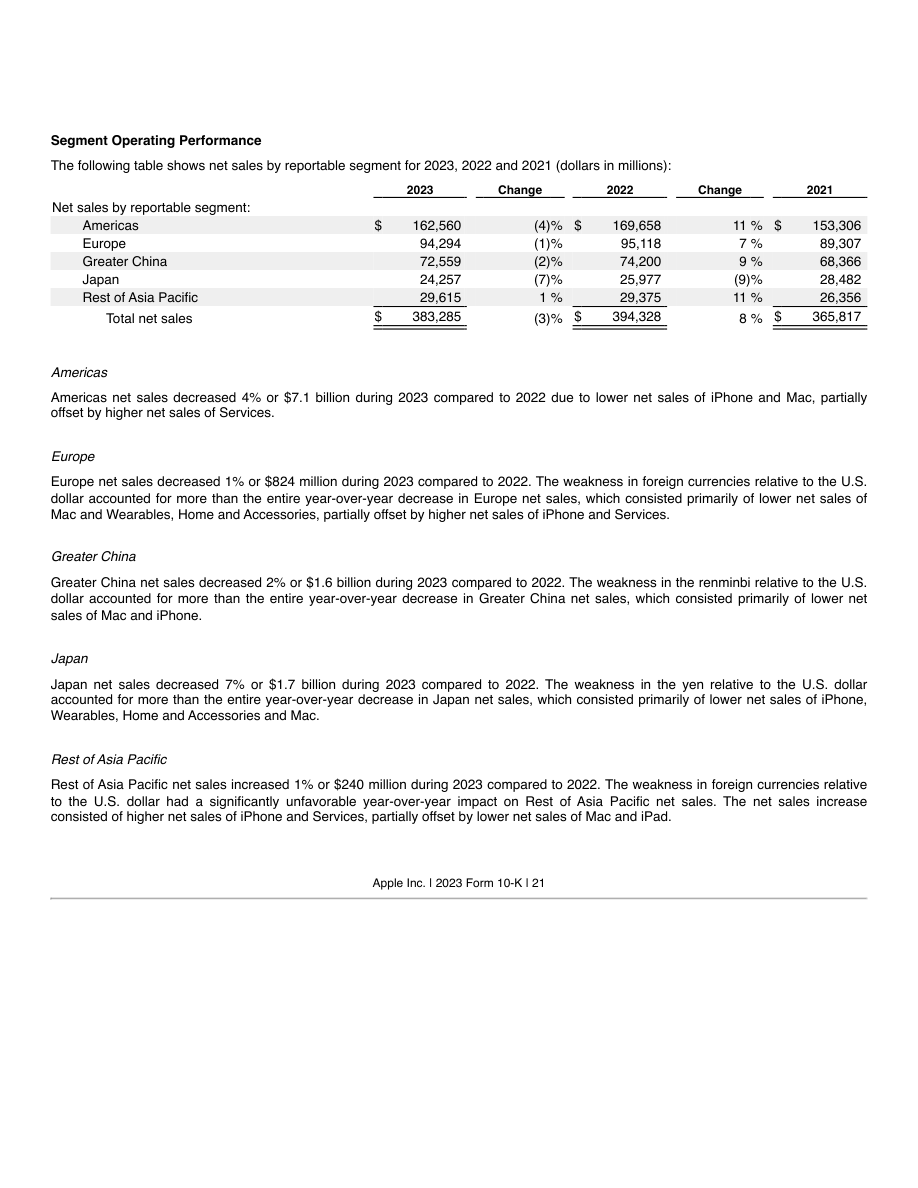

Segment Operating Performance

The following table shows net sales by reportable segment for 2023, 2022 and 2021 (dollars in millions):

                                                     2023         Change          2022         Change          2021
Net sales by reportable segment:
     Americas                               $    162,560          (4)%  $    169,658          11 %  $    153,306
    Europe                                           94,294          (1)%         95,118          7 %        89,307
     Greater China                                     72,559          (2)%        74,200          9 %        68,366
    Japan                                            24,257          (7)%        25,977          (9)%        28,482
     Rest of Asia Pacific                                29,615          1 %        29,375          11 %        26,356
          Total net sales                        $    383,285          (3)%  $    394,328          8 %  $    365,817



Americas

Ame

In [3]:
import pymupdf
from IPython.display import display, Image

pdf_path = PROJECT_ROOT / "data/documents/apple_10k.pdf"

with pymupdf.open(pdf_path) as doc:
    page = doc[31]  # Physical page 32

    # Display the actual page
    pix = page.get_pixmap(matrix=pymupdf.Matrix(1.5, 1.5))
    display(Image(data=pix.tobytes("png")))

    # Extract text from the same page
    text = page.get_text("text", sort=True)
    print(text)

## Implementation — construct page-labeled evidence

The physical page number is inserted next to the text before generation. The context is deliberately bounded to one retrieved page for this wiring experiment.

In [2]:
retrieved_page_numbers = [49]
with pymupdf.open(SLIDES_PDF) as document:
    retrieved_pages = [
        {
            "page_number": page_number,
            "text": document[page_number - 1].get_text("text", sort=True),
        }
        for page_number in retrieved_page_numbers
    ]

context_blocks = [
    f"[Page {page['page_number']}]\n{page['text'].strip()}"
    for page in retrieved_pages
]
text_context = "\n\n".join(context_blocks)
print(text_context[:700])

[Page 49]
Exponential Families. X


Usual conjugate pairs. n i.i.d. observations. Notation: s := Pi xi,
Q := Pi(xi −µ)2, x(n) := maxi xi, (s1, . . . , sk) the category counts. Ga(a, b): shape
a, rate b, mean a/b. InvGa(a, b): law of 1/V for V ∼Ga(a, b), density
∝v−a−1e−b/v. Pareto(a, b): density ∝θ−a−11θ≥b.


    Sampling model             Prior →Posterior                                  Prior sample size

     Bernoulli(θ)              Beta(a, b) →Beta(a + s, b + n −s)           a + b
    Poisson(λ)             Ga(a, b) →Ga(a + s, b + n)                 b
    Exponential(λ)          Ga(a, b) →Ga(a + n, b + s)                 a
   N(θ, σ2), σ2 known     N(µ0, σ2 ) →N  n0µ0+n¯x ,  σ2        


## Implementation — define the response contract

In [3]:
question = "Which physical page contains the table titled 'Usual conjugate pairs'?"

system_instruction = (
    "Answer only from the supplied page text. "
    "Cite every factual claim using [Page N]. "
    "If the evidence is insufficient, say so instead of guessing."
)
user_message = f"{question}\n\nEvidence:\n{text_context}"

prompt_summary = {
    "system_instruction": system_instruction,
    "question": question,
    "allowed_pages": retrieved_page_numbers,
    "context_characters": len(text_context),
    "model_provider_configured": MODEL_PROVIDER is not None and MODEL_NAME is not None,
}
prompt_summary

{'system_instruction': 'Answer only from the supplied page text. Cite every factual claim using [Page N]. If the evidence is insufficient, say so instead of guessing.',
 'question': "Which physical page contains the table titled 'Usual conjugate pairs'?",
 'allowed_pages': [49],
 'context_characters': 1435,
 'model_provider_configured': False}

## Execution — citation parser wiring

The response below is explicitly a deterministic mock used to test the interface. It is not a model result and must not enter evaluation data.

In [4]:
mock_response = "The table appears on physical page 49 [Page 49]."

cited_pages = [int(page) for page in re.findall(r"\[Page (\d+)\]", mock_response)]
allowed_pages = set(retrieved_page_numbers)
invalid_citations = sorted(set(cited_pages) - allowed_pages)

response_check = {
    "response": mock_response,
    "cited_pages": cited_pages,
    "invalid_citations": invalid_citations,
    "has_citation": bool(cited_pages),
}
response_check

{'response': 'The table appears on physical page 49 [Page 49].',
 'cited_pages': [49],
 'invalid_citations': [],
 'has_citation': True}

## Inspection and interpretation

The parser verifies citation format and whether cited pages were supplied. It does not prove that page 49 supports the wording of every claim. Evidence correctness still requires comparison with human annotations or manual review.

## Validation — valid and invalid citations

In [5]:
assert cited_pages == [49]
assert not invalid_citations
assert "Usual conjugate pairs" in text_context

invalid_mock_response = "The table appears here [Page 999]."
invalid_pages = [int(page) for page in re.findall(r"\[Page (\d+)\]", invalid_mock_response)]
assert set(invalid_pages) - allowed_pages == {999}

print("Citation format and allowed-page checks behave as intended.")

Citation format and allowed-page checks behave as intended.


## Model execution gate

No model is called because provider and model choices are still open research parameters. When selected, record provider, exact model version, temperature, prompt version, request timestamp, latency, and cost in the notebook before interpreting outputs.

In [6]:
model_call_ready = MODEL_PROVIDER is not None and MODEL_NAME is not None
print("Model call ready:", model_call_ready)

Model call ready: False


## Next step

`09_multimodal_qa_with_citations.ipynb` renders the same evidence page and constructs the image-side input while keeping the question and citation contract fixed.